# 08a · ONNX export, parity and latency
Phase 8a of 10. No training. Exports the frozen 7a M0 ensembles to ONNX, checks parity against PyTorch and the 7a verdicts, and times CPU inference. The S6 expectations are registered in S0, before any parity or timing number exists.

In [1]:
# S0 · setup, installs (uv), hash guards, helpers, pre-registered expectations
import os, sys, json, time, gc, shutil, hashlib, importlib, importlib.util, inspect, platform, subprocess, textwrap, datetime as dt
from pathlib import Path
sys.dont_write_bytecode = True
T0 = time.time()

SMOKE = False   # True: 2,000 rows, 50 timing repeats, outputs/phase8a/smoke/. Smoke results are never quoted.
REPEATS, WARMUP = (50, 20) if SMOKE else (5000, 200)
MIN_REP = min(100, REPEATS)
BUDGET_S = 3.0  # per-configuration time cap; repeats fall below 5,000 only if 5,000 calls would exceed it (the count is reported)

_missing = [p for p in ("onnx", "onnxruntime", "onnxscript", "psutil") if importlib.util.find_spec(p) is None]
if _missing:
    _uv = shutil.which("uv")
    if _uv is None:
        raise RuntimeError(f"missing packages {_missing} and uv is not on PATH: install uv or add them to .venv")
    print("uv pip install", _missing)
    subprocess.run([_uv, "pip", "install", "--python", sys.executable, *_missing], check=True)
    importlib.invalidate_caches()

import numpy as np, pandas as pd, psutil, torch
import onnx, onnxruntime as ort, onnxscript
from onnx import helper, TensorProto, numpy_helper
from onnxruntime.quantization import quantize_dynamic, QuantType
import matplotlib.pyplot as plt

# ---- paths
_cwd = Path.cwd().resolve()
ROOT = next((p for p in [_cwd, *_cwd.parents] if (p / "notebooks").is_dir() and (p / "data").is_dir()), None)
if ROOT is None:
    raise RuntimeError(f"project root not found: no folder in {_cwd} or its parents contains both notebooks/ and data/")
OUT7A = ROOT / "outputs" / "phase7a"
OUT_BASE = ROOT / "outputs" / "phase8a"
OUT = OUT_BASE / "smoke" if SMOKE else OUT_BASE
MODELS_DIR = OUT / "models"
SRC = ROOT / "src"
SCORER_PATH = SRC / "onnx_scorer.py"
LOG_PATH = OUT / "phase8a_log.jsonl"
OUT.mkdir(parents=True, exist_ok=True)

def W(path):
    p = Path(path).resolve()
    if OUT_BASE.resolve() not in p.parents and p != SCORER_PATH.resolve():
        raise PermissionError(f"write refused (outside outputs/phase8a and src/onnx_scorer.py): {p}")
    p.parent.mkdir(parents=True, exist_ok=True)
    return p
def _jd(o):
    if isinstance(o, np.integer): return int(o)
    if isinstance(o, np.floating): return float(o)
    if isinstance(o, np.bool_): return bool(o)
    if isinstance(o, np.ndarray): return o.tolist()
    if isinstance(o, (set, tuple)): return sorted(o) if isinstance(o, set) else list(o)
    if isinstance(o, Path): return str(o)
    raise TypeError(type(o))
def write_text(path, text): W(path).write_text(text, encoding="utf-8", newline="\n")
def write_json(path, obj): write_text(path, json.dumps(obj, indent=2, sort_keys=True, default=_jd) + "\n")
def sha256_bytes(b): return hashlib.sha256(b).hexdigest()
def sha256_file(p): return sha256_bytes(Path(p).read_bytes())
def now_utc(): return dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds")

# ---- checks, tables, report buffers
CHECKS, EXTRA, TABLES = [], {}, []
class CheckFail(RuntimeError): pass
def dump_report(failed=None):
    rep = dict(created_utc=now_utc(), smoke=SMOKE, failed=failed, checks=CHECKS, extra=EXTRA, elapsed_s=round(time.time() - T0, 1))
    write_json(OUT / "verification_report.json", rep)
    n = {k: sum(c["status"] == k for c in CHECKS) for k in ("PASS", "WARN", "FAIL")}
    print("REPORT DUMPED:", n)
def check(name, ok, detail="", warn_only=False):
    status = "PASS" if ok else ("WARN" if warn_only else "FAIL")
    CHECKS.append(dict(name=name, status=status, detail=str(detail)))
    print(f"[{status}] {name}" + (f" - {detail}" if str(detail) else ""))
    if status == "FAIL":
        dump_report(failed=name)
        raise CheckFail(f"{name}: {detail}")
def emit(title, text):
    print(f"\n{title}\n" + "-" * len(title))
    print(text)
    TABLES.append((title, text))
def show_table(title, df, nd=6):
    emit(title, df.to_string(index=False, float_format=lambda v: f"{v:.{nd}g}"))

# ---- append-only hash-chained log (same scheme as 7a/7b/7c)
def log_entries():
    if not LOG_PATH.exists(): return []
    return [json.loads(l) for l in LOG_PATH.read_text(encoding="utf-8").splitlines() if l.strip()]
def log_append(event, **kw):
    prev = ""
    if LOG_PATH.exists():
        lines = [l for l in LOG_PATH.read_text(encoding="utf-8").splitlines() if l.strip()]
        prev = sha256_bytes(lines[-1].encode("utf-8")) if lines else ""
    entry = dict(t_utc=now_utc(), event=event, prev_line_sha256=prev, **kw)
    with open(W(LOG_PATH), "a", encoding="utf-8", newline="\n") as f:
        f.write(json.dumps(entry, sort_keys=True, default=_jd) + "\n")
    return entry

# ---- environment
CUDA = torch.cuda.is_available()
TORCH_THREADS = torch.get_num_threads()
_free = torch.cuda.mem_get_info()[0] / 2**30 if CUDA else float("nan")
VERSIONS = dict(python=platform.python_version(), numpy=np.__version__, pandas=pd.__version__, torch=torch.__version__,
                onnx=onnx.__version__, onnxruntime=ort.__version__, onnxscript=getattr(onnxscript, "__version__", "n/a"))
env = [dict(item=k, value=v) for k, v in VERSIONS.items()] + [
    dict(item="CUDA available", value=CUDA),
    dict(item="device", value=torch.cuda.get_device_name(0) if CUDA else "none (CPU only)"),
    dict(item="free VRAM (GB)", value=round(_free, 2) if CUDA else "n/a"),
    dict(item="CPU count (logical / physical)", value=f"{os.cpu_count()} / {psutil.cpu_count(logical=False)}"),
    dict(item="torch CPU threads (default)", value=TORCH_THREADS),
    dict(item="ONNX Runtime providers", value=",".join(ort.get_available_providers())),
    dict(item="SMOKE", value=SMOKE), dict(item="ROOT", value=str(ROOT)), dict(item="OUT", value=str(OUT))]
show_table("Environment", pd.DataFrame(env))
check("CUDA available (extra rows only; all latency numbers are CPU)", CUDA, f"torch.cuda.is_available() = {CUDA}", warn_only=True)

# ---- hash guards (start and end)
def _find_cfg(expected, label):
    cands = sorted(set((ROOT / "outputs").rglob("monitor_config*.json")) | set(ROOT.glob("monitor_config*.json")) | set((ROOT / "config").glob("monitor_config*.json")) | set((ROOT / "configs").glob("monitor_config*.json")))
    hits = [p for p in cands if sha256_file(p) == expected]
    if not hits:
        check(f"locate {label}", False, f"no file with sha256 {expected}; candidates: " + ("; ".join(f"{p.relative_to(ROOT)}={sha256_file(p)}" for p in cands) or "none found"))
    return hits[0]
GUARD = {
    "M0_W240.npz": (OUT7A / "models" / "M0_W240.npz", "29cd3ec8c5c2113db1d1b3562365461f3045f07b5e3113532f28eeff34c744fe"),
    "M0_W300.npz": (OUT7A / "models" / "M0_W300.npz", "06f63dc6c5a89750d18622099961e875ee1aeb1b65d9afe16b556f0d7cb149c2"),
    "M0idx_W240.npz": (OUT7A / "models" / "M0idx_W240.npz", "b7822335aa1c7cb592e4a12e3044c614a3b2616b2a5be5c940b47579862f8e18"),
    "M0idx_W300.npz": (OUT7A / "models" / "M0idx_W300.npz", "0e7430ee1586a57b38207ce95e7d73b902b230678a92c0f32a4a704e5c05e99e"),
    "batch3_predictions.parquet": (OUT7A / "batch3_predictions.parquet", "679ec76862de63f2615a710c7fc1f3ca2ec6c01149735bdd909b95ad5a9c7acd"),
    "soh_deep_v4.py": (SRC / "soh_deep_v4.py", "2be9ce5ded197b16028079e7d34b550c683f4152b528f55f5064251b146eded4"),
}
GUARD["monitor_config"] = (_find_cfg("638b6c3a6ad31c699fb77a22eb9fae72b571d6dc21ee65a73b41e849d7acb4b2", "monitor_config"), "638b6c3a6ad31c699fb77a22eb9fae72b571d6dc21ee65a73b41e849d7acb4b2")
GUARD["monitor_config_addendum"] = (_find_cfg("d842e5f4c3186889ce8292e0654e1a0ca29d4434bcdeaf1bd3c7131479479632", "monitor_config_addendum"), "d842e5f4c3186889ce8292e0654e1a0ca29d4434bcdeaf1bd3c7131479479632")
def guard(tag):
    rows = []
    for k, (p, h) in GUARD.items():
        got = sha256_file(p) if p.is_file() else None
        rows.append(dict(item=k, path=str(p.relative_to(ROOT)), expected=h[:16], got=(got or "MISSING")[:16], match=got == h))
        check(f"[{tag}] sha256 {k}", got == h, f"{p.name}: got {got}")
    return pd.DataFrame(rows)
GUARD_START = guard("start")
show_table("Hash guard (start)", GUARD_START)

# ---- expectations, registered before any parity or timing number exists (S6 reports observed vs expected)
EXPECT = [
    dict(id="H12", statement="ONNX Runtime CPU vs PyTorch fp32, max |difference| over all 96,419 stored rows, worst of the four models", expected="< 1e-3 pp"),
    dict(id="H13", statement="deployed M0 W240, ONNX Runtime CPU intra_op=1, batch 1", expected="median < 1 ms and p99 < 5 ms"),
    dict(id="H14", statement="deployed M0 W240, ONNX Runtime CPU intra_op=1, one call with 124 rows (all cells)", expected="median < 5 ms"),
    dict(id="H15", statement="int8 dynamic quantisation of deployed M0 W240, change in batch-3 cell-macro MAE", expected="|change| < 0.02 pp"),
]
write_json(OUT / "expectations_registered.json", dict(created_utc=now_utc(), smoke=SMOKE, expectations=EXPECT))
EXPECT_SHA = sha256_file(OUT / "expectations_registered.json")
show_table("Expectations registered before parity and timing", pd.DataFrame(EXPECT))
log_append("start", smoke=SMOKE, versions=VERSIONS, expectations_sha256=EXPECT_SHA,
           hashes={k: sha256_file(p) for k, (p, h) in GUARD.items()}, root=str(ROOT))
print("log:", LOG_PATH, "| entries:", len(log_entries()))


Environment
-----------
                          item                                                             value
                        python                                                           3.13.13
                         numpy                                                             2.5.4
                        pandas                                                             3.1.0
                         torch                                                      2.14.1+cu130
                          onnx                                                            1.23.2
                   onnxruntime                                                            1.31.1
                    onnxscript                                                             0.7.2
                CUDA available                                                              True
                        device                            NVIDIA GeForce RTX 3050 6GB Laptop GPU
     

## S1 · Rebuild the PyTorch ensembles and match the 7a predictions

In [2]:
# S1a · frozen module, labels, stored features, 7a reference predictions
sys.path.insert(0, str(SRC))
import soh_deep_v4 as sd4
import re
import pyarrow.dataset as pds
import pyarrow.parquet as pq

def _sig(o):
    try: return str(inspect.signature(o))
    except (TypeError, ValueError) as e: return f"(unavailable: {e})"
_objs = [("soh_deep_v4.sub_idx", sd4.sub_idx), ("soh_deep_v4.make_single", sd4.make_single), ("soh_deep_v4.SingleM0.__init__", sd4.SingleM0.__init__),
         ("soh_deep_v4.SingleM0.forward", sd4.SingleM0.forward), ("soh_deep_v4._qcols", sd4._qcols), ("soh_deep_v4.count_params", sd4.count_params),
         ("onnx.helper.make_node", helper.make_node), ("onnx.helper.make_tensor_value_info", helper.make_tensor_value_info), ("onnx.helper.make_graph", helper.make_graph),
         ("onnx.helper.make_model", helper.make_model), ("onnx.checker.check_model", onnx.checker.check_model),
         ("onnxruntime.InferenceSession", ort.InferenceSession), ("onnxruntime.quantization.quantize_dynamic", quantize_dynamic),
         ("pyarrow.dataset.dataset", pds.dataset), ("numpy.load", np.load)]
show_table("Signatures of helpers used", pd.DataFrame([dict(helper=n, signature=_sig(o)) for n, o in _objs]))
check("soh_deep_v4 on disk is the guarded file", sd4.self_hash() == GUARD["soh_deep_v4.py"][1], f"self_hash {sd4.self_hash()[:16]}")

# architecture from the module itself
EXP_SHAPES = {False: [("fc1.weight", (44, 33)), ("fc1.bias", (44,)), ("fc2.weight", (32, 44)), ("fc2.bias", (32,)), ("fc3.weight", (1, 32)), ("fc3.bias", (1,))],
              True:  [("fc1.weight", (44, 34)), ("fc1.bias", (44,)), ("fc2.weight", (32, 44)), ("fc2.bias", (32,)), ("fc3.weight", (1, 32)), ("fc3.bias", (1,))]}
arch = []
for idx, n_par in ((False, 2969), (True, 3013)):
    m = sd4.make_single("M0", 734, 42, torch.float32, int(idx))
    got = [(n, tuple(p.shape)) for n, p in m.named_parameters()]
    arch += [dict(model="M0+idx" if idx else "M0", layer=n, shape=str(s)) for n, s in got]
    check(f"module architecture {'M0+idx 34->44->32->1' if idx else 'M0 33->44->32->1'}", got == EXP_SHAPES[idx] and sd4.count_params(m) == n_par,
          f"shapes {got}, count_params {sd4.count_params(m)} (expected {n_par})")
show_table("M0 architecture read from the module", pd.DataFrame(arch))

# ---- label table, development and batch-3 cells, row order exactly as in 7a
WIDTH = {"W300": 334, "W240": 734}
LABELS = ROOT / "data" / "processed" / "labels_table_v2.parquet"
for p in (LABELS, ROOT / "data" / "processed" / "splits" / "protocol_D.csv"):
    check(f"input exists: {p.name}", p.is_file(), str(p))
_ds = pds.dataset(str(LABELS))
def _bnum(v):
    if isinstance(v, (int, float, np.integer, np.floating)): return int(v)
    m = re.search(r"\d+", str(v)); return int(m.group()) if m else -1
lab = _ds.to_table(columns=["row_id", "cell_id", "batch", "cycle_number", "q0", "scored2"]).to_pandas()
lab["batch_i"] = lab["batch"].map(_bnum)
lab["scored2"] = lab["scored2"].astype(bool)
DEV_CELLS = sorted(pd.read_csv(ROOT / "data" / "processed" / "splits" / "protocol_D.csv").cell_id.unique())
B3_CELLS = sorted(lab.loc[lab.scored2 & (lab.batch_i == 3), "cell_id"].unique())
if len(B3_CELLS) != 40:   # same restriction as 7a: keep cells in the Phase 3 kept list
    _kept = set(pd.read_csv(ROOT / "outputs" / "phase3" / "kept_cells_groups_strata.csv").cell_id)
    print(f"batch-3 scored cells: {len(B3_CELLS)}; restricting to kept list")
    B3_CELLS = [c for c in B3_CELLS if c in _kept]
DEV_SET, B3_SET = set(DEV_CELLS), set(B3_CELLS)
ROWS = (lab[lab.scored2 & lab.cell_id.isin(DEV_SET | B3_SET)].sort_values(["cell_id", "cycle_number", "row_id"]).reset_index(drop=True))
del lab
N = len(ROWS)
ROW_ID = ROWS.row_id.to_numpy(np.int64)
CELLID = ROWS.cell_id.to_numpy(object)
IS_B3 = ROWS.cell_id.isin(B3_SET).to_numpy()
B3_POS = np.flatnonzero(IS_B3)
n_dev, n_b3 = int((~IS_B3).sum()), int(IS_B3.sum())
check("84 development cells", len(DEV_CELLS) == 84, len(DEV_CELLS))
check("40 batch-3 cells", len(B3_CELLS) == 40, len(B3_CELLS))
check("no cell in both sets", not (DEV_SET & B3_SET), f"{len(DEV_SET & B3_SET)} shared")
check("scored rows: dev 55,963, batch 3 40,456, total 96,419", (n_dev, n_b3, N) == (55963, 40456, 96419), f"dev {n_dev:,}, batch 3 {n_b3:,}, total {N:,}")
Q0_32 = ROWS.q0.to_numpy(np.float64).astype(np.float32)
CYC = ROWS.cycle_number.to_numpy(np.float64)
LOGC32 = np.log1p(CYC).astype(np.float32)
check("q0 and cycle_number finite", bool(np.isfinite(Q0_32).all() and np.isfinite(LOGC32).all()))
FLEET_POS = ROWS.groupby("cell_id", sort=False).tail(1).index.to_numpy()   # last scored row of each cell
check("fleet snapshot is 124 rows (one per cell)", len(FLEET_POS) == 124, len(FLEET_POS))

# ---- stored DeltaQ blocks (read-only memory maps)
ROWKEY = hashlib.sha1(ROW_ID.tobytes()).hexdigest()[:12]
DQ_MM, GRID = {}, {}
for w in WIDTH:
    f = OUT7A / "cache" / f"dq_{w}_{ROWKEY}.npy"
    if not f.is_file():
        raise RuntimeError(f"stored feature block not found: {f}. Row-order key {ROWKEY} built as in 7a (sorted by cell_id, cycle_number, row_id). Files present: "
                           + ", ".join(sorted(p.name for p in (OUT7A / "cache").glob(f"dq_{w}_*.npy"))))
    DQ_MM[w] = np.load(f, mmap_mode="r")
    GRID[w] = np.asarray(sd4.sub_idx(WIDTH[w]), np.int64)
    check(f"stored DeltaQ block {w}", DQ_MM[w].shape == (N, WIDTH[w]) and DQ_MM[w].dtype == np.float32, f"{f.name} shape {DQ_MM[w].shape} dtype {DQ_MM[w].dtype}")

# ---- row subset (full run: every stored row; smoke: 2,000 rows)
IDX_ALL = np.sort(np.random.default_rng(0).choice(N, 2000, replace=False)) if SMOKE else np.arange(N)
B3_IN = np.flatnonzero(IS_B3[IDX_ALL])
B3_RIDS = ROW_ID[IDX_ALL[B3_IN]]
B3_CELL_ARR = CELLID[IDX_ALL[B3_IN]]
print(f"rows used for parity: {len(IDX_ALL):,} (batch 3: {len(B3_IN):,})")
def read_rows(w, pos):
    pos = np.asarray(pos, np.int64)
    if len(pos) and pos[-1] - pos[0] + 1 == len(pos) and np.all(np.diff(pos) == 1):
        return np.array(DQ_MM[w][pos[0]:pos[-1] + 1])
    return np.asarray(DQ_MM[w][pos])
def get_inputs(w, pos):
    dq_full = read_rows(w, pos)
    return dq_full, dq_full[:, GRID[w]], Q0_32[pos], LOGC32[pos]

# ---- 7a reference predictions (per seed) and batch-3 labels (descriptive reproduction only)
sch = pq.read_schema(OUT7A / "batch3_predictions.parquet")
emit("batch3_predictions.parquet columns", "\n".join(f"{n}: {t}" for n, t in zip(sch.names, sch.types)))
need = {"model", "window", "seed", "row_id", "pred_pp"}
check("predictions parquet has the needed columns", need <= set(sch.names), f"columns {sch.names}")
PRED = pd.read_parquet(OUT7A / "batch3_predictions.parquet", columns=sorted(need))
PRED = PRED[PRED.model.isin(["M0", "M0idx"])]
MODELS = {"M0_W240": dict(pm="M0", w="W240", idx=False), "M0_W300": dict(pm="M0", w="W300", idx=False),
          "M0idx_W240": dict(pm="M0idx", w="W240", idx=True), "M0idx_W300": dict(pm="M0idx", w="W300", idx=True)}
B3_RID_ALL = ROW_ID[B3_POS]
REF_SEED, REF_MEAN, ref_rows = {}, {}, []
for name, d in MODELS.items():
    g = PRED[(PRED.model == d["pm"]) & (PRED.window == d["w"])]
    piv = g.pivot(index="row_id", columns="seed", values="pred_pp").reindex(B3_RID_ALL)
    check(f"7a predictions complete [{name}]", piv.shape == (n_b3, 5) and bool(piv.notna().all().all()), f"shape {piv.shape}, seeds {list(piv.columns)}")
    REF_SEED[name] = piv
    REF_MEAN[name] = piv.mean(axis=1)
    ref_rows.append(dict(model=name, rows=len(piv), seeds=",".join(str(s) for s in piv.columns)))
del PRED
show_table("7a reference predictions", pd.DataFrame(ref_rows))
_y = _ds.to_table(columns=["row_id", "soh_nom"], filter=pds.field("row_id").isin([int(r) for r in B3_RID_ALL])).to_pandas().set_index("row_id").soh_nom
Y_B3 = 100.0 * _y.reindex(B3_RID_ALL).astype(np.float64)
del _y
check("batch-3 labels complete (descriptive reproduction only; nothing is selected with them)", bool(Y_B3.notna().all()) and len(Y_B3) == n_b3, f"{len(Y_B3):,} rows")
Y_SUB = Y_B3.reindex(B3_RIDS).to_numpy()
def cell_macro(pred, y, cells):
    e = pd.Series(np.abs(np.asarray(pred, np.float64) - np.asarray(y, np.float64)))
    return float(e.groupby(np.asarray(cells)).mean().mean())


Signatures of helpers used
--------------------------
                                   helper                                                                                                                                                                                                                                                                                                                                             signature
                      soh_deep_v4.sub_idx                                                                                                                                                                                                                                                                                                                                                   (L)
                  soh_deep_v4.make_single                                                                                                                                        

In [3]:
# S1b · load the four npz files, rebuild each ensemble with the module's own classes, compare with 7a
MODEL_FILES_NPZ = {n: OUT7A / "models" / f"{n}.npz" for n in MODELS}
SCALERS = ["s", "qm", "qs", "ym", "ys"]
def load_npz(path, name):
    z = np.load(path, allow_pickle=False)
    files = list(z.files)
    st = {k: z[k] for k in files}
    meta = json.loads(str(st["meta"]))
    n_extra = int(meta["n_extra"])
    scn = SCALERS + (["em", "es"] if n_extra else [])
    need = ["seeds", "grid", "meta"] + [f"scaler_{k}" for k in scn] + [f"m{g}_{l}_{t}" for g in range(5) for l in ("fc1", "fc2", "fc3") for t in ("w", "b")]
    miss = [k for k in need if k not in st]
    if miss: raise RuntimeError(f"{name}: npz is missing keys {miss}; present: {files}")
    d_in = 33 + n_extra
    shp = {"fc1_w": (44, d_in), "fc1_b": (44,), "fc2_w": (32, 44), "fc2_b": (32,), "fc3_w": (1, 32), "fc3_b": (1,)}
    for g in range(5):
        for k, s in shp.items():
            a = st[f"m{g}_{k}"]
            if a.shape != s or a.dtype != np.float32:
                raise RuntimeError(f"{name}: m{g}_{k} has shape {a.shape} dtype {a.dtype}, expected {s} float32")
    for k in scn:
        a = st[f"scaler_{k}"]
        if a.shape != (5,) or a.dtype != np.float32: raise RuntimeError(f"{name}: scaler_{k} has shape {a.shape} dtype {a.dtype}, expected (5,) float32")
    st.update(n_extra=n_extra, scaler_names=scn, meta_d=meta, files=files)
    return st
STATE, meta_rows = {}, []
for name, d in MODELS.items():
    st = load_npz(MODEL_FILES_NPZ[name], name)
    emit(f"npz keys: {name}.npz ({len(st['files'])} keys)", textwrap.fill(", ".join(sorted(st["files"])), 110))
    m = st["meta_d"]
    check(f"npz metadata [{name}]", m["kind"] == "M0" and m["head"] == "abs" and int(m["L"]) == WIDTH[d["w"]] and m["window"] == d["w"] and bool(st["n_extra"]) == d["idx"]
          and np.array_equal(st["grid"], GRID[d["w"]]) and [int(s) for s in st["seeds"]] == [42, 43, 44, 45, 46],
          f"kind {m['kind']}, head {m['head']}, L {m['L']}, window {m['window']}, n_extra {st['n_extra']}, seeds {[int(s) for s in st['seeds']]}, grid==sub_idx(L) {np.array_equal(st['grid'], GRID[d['w']])}")
    meta_rows.append(dict(model=name, kind=m["kind"], window=m["window"], L=m["L"], n_extra=m["n_extra"], head=m["head"], lr=m["lr"], wd=m["wd"], epochs=m["epochs"], trained_on=m["trained_on"]))
    STATE[name] = st
show_table("npz metadata", pd.DataFrame(meta_rows))

def build_members(st, L):
    mods = []
    for g in range(5):
        m = sd4.make_single("M0", L, int(st["seeds"][g]), torch.float32, st["n_extra"])
        with torch.no_grad():
            for nm in ("fc1", "fc2", "fc3"):
                getattr(m, nm).weight.copy_(torch.from_numpy(st[f"m{g}_{nm}_w"].copy()))
                getattr(m, nm).bias.copy_(torch.from_numpy(st[f"m{g}_{nm}_b"].copy()))
        mods.append(m.eval())
    return mods
@torch.inference_mode()
def torch_member_preds(mods, st, dq_full, q0, logc):
    d_t, q_t, e_t = torch.from_numpy(dq_full), torch.from_numpy(q0), torch.from_numpy(logc)
    out = np.empty((len(mods), len(q0)), np.float32)
    for g, m in enumerate(mods):
        sc = {k: torch.as_tensor(st[f"scaler_{k}"][g]) for k in st["scaler_names"]}
        d = d_t / sc["s"]
        q = (q_t - sc["qm"]) / sc["qs"]
        if st["n_extra"]: q = torch.stack([q, (e_t - sc["em"]) / sc["es"]], 1)
        out[g] = (sc["ym"] + sc["ys"] * m(d, q)).numpy()    # head "abs": ym + ys * z
    return out

CH = 20000
TORCH_MEMBER, TORCH_MEAN, INP = {}, {}, {}
for w in ("W300", "W240"):
    names = [n for n in MODELS if MODELS[n]["w"] == w]
    mods = {n: build_members(STATE[n], WIDTH[w]) for n in names}
    dq32 = np.empty((len(IDX_ALL), 32), np.float32)
    mem = {n: np.empty((5, len(IDX_ALL)), np.float32) for n in names}
    for a in range(0, len(IDX_ALL), CH):
        pos = IDX_ALL[a:a + CH]
        dq_full = read_rows(w, pos)
        dq32[a:a + CH] = dq_full[:, GRID[w]]
        for n in names:
            mem[n][:, a:a + CH] = torch_member_preds(mods[n], STATE[n], dq_full, Q0_32[pos], LOGC32[pos])
    INP[w] = dict(dq32=dq32, q0=np.ascontiguousarray(Q0_32[IDX_ALL].reshape(-1, 1)), logc=np.ascontiguousarray(LOGC32[IDX_ALL].reshape(-1, 1)))
    for n in names:
        TORCH_MEMBER[n] = mem[n]
        TORCH_MEAN[n] = mem[n].astype(np.float64).mean(0)

rows1 = []
for name, d in MODELS.items():
    ref = REF_SEED[name].loc[B3_RIDS].to_numpy(np.float64)                # (n, 5) per-seed 7a predictions
    mine = TORCH_MEMBER[name][:, B3_IN].T.astype(np.float64)
    ps = np.abs(mine - ref)
    em = np.abs(TORCH_MEAN[name][B3_IN] - REF_MEAN[name].loc[B3_RIDS].to_numpy(np.float64))
    rows1.append(dict(model=name, rows=len(B3_IN), per_seed_max_pp=ps.max(), per_seed_median_pp=np.median(ps), ens_mean_max_pp=em.max(), ens_mean_median_pp=np.median(em)))
    check(f"PyTorch rebuild reproduces 7a to 1e-4 pp [{name}]", max(ps.max(), em.max()) <= 1e-4,
          f"per-seed max {ps.max():.2e}, median {np.median(ps):.2e}; ensemble mean max {em.max():.2e}, median {np.median(em):.2e} (rows {len(B3_IN):,})")
S1_TABLE = pd.DataFrame(rows1)
show_table("S1 · PyTorch rebuild vs 7a batch3_predictions.parquet (pp)", S1_TABLE, 4)
EXTRA["s1_pytorch_vs_7a"] = rows1


npz keys: M0_W240.npz (38 keys)
-------------------------------
grid, m0_fc1_b, m0_fc1_w, m0_fc2_b, m0_fc2_w, m0_fc3_b, m0_fc3_w, m1_fc1_b, m1_fc1_w, m1_fc2_b, m1_fc2_w,
m1_fc3_b, m1_fc3_w, m2_fc1_b, m2_fc1_w, m2_fc2_b, m2_fc2_w, m2_fc3_b, m2_fc3_w, m3_fc1_b, m3_fc1_w, m3_fc2_b,
m3_fc2_w, m3_fc3_b, m3_fc3_w, m4_fc1_b, m4_fc1_w, m4_fc2_b, m4_fc2_w, m4_fc3_b, m4_fc3_w, meta, scaler_qm,
scaler_qs, scaler_s, scaler_ym, scaler_ys, seeds
[PASS] npz metadata [M0_W240] - kind M0, head abs, L 734, window W240, n_extra 0, seeds [42, 43, 44, 45, 46], grid==sub_idx(L) True

npz keys: M0_W300.npz (38 keys)
-------------------------------
grid, m0_fc1_b, m0_fc1_w, m0_fc2_b, m0_fc2_w, m0_fc3_b, m0_fc3_w, m1_fc1_b, m1_fc1_w, m1_fc2_b, m1_fc2_w,
m1_fc3_b, m1_fc3_w, m2_fc1_b, m2_fc1_w, m2_fc2_b, m2_fc2_w, m2_fc3_b, m2_fc3_w, m3_fc1_b, m3_fc1_w, m3_fc2_b,
m3_fc2_w, m3_fc3_b, m3_fc3_w, m4_fc1_b, m4_fc1_w, m4_fc2_b, m4_fc2_w, m4_fc3_b, m4_fc3_w, meta, scaler_qm,
scaler_qs, scaler_s, scaler_ym, scaler_ys, 

## S2 · Export
One ONNX graph per model: five members, scalers and ensemble mean, raw inputs. Weights are written straight from the npz arrays; equality with the npz tensors and the list of files opened are asserted.

In [4]:
# S2 · build the four graphs from the npz tensors, check, save, hash, log
def build_onnx(st, uses_idx, linear="gemm", doc=""):
    G = len(st["seeds"])
    inits, nodes = [], []
    def init(nm, arr):
        arr = np.asarray(arr)
        if arr.ndim: arr = np.ascontiguousarray(arr)      # keep scalars 0-d (ascontiguousarray would make them shape (1,))
        inits.append(numpy_helper.from_array(arr, name=nm)); return nm
    F = TensorProto.FLOAT
    inputs = [helper.make_tensor_value_info("dq32", F, ["N", 32]), helper.make_tensor_value_info("q0", F, ["N", 1])]
    if uses_idx: inputs.append(helper.make_tensor_value_info("log_cycle", F, ["N", 1]))
    preds = []
    for g in range(G):
        p = f"m{g}_"
        sc = {k: init(f"w_{p}{k}", np.asarray(st[f"scaler_{k}"][g], np.float32)) for k in st["scaler_names"]}
        nodes += [helper.make_node("Div", ["dq32", sc["s"]], [p + "xd"]),
                  helper.make_node("Sub", ["q0", sc["qm"]], [p + "qc"]), helper.make_node("Div", [p + "qc", sc["qs"]], [p + "xq"])]
        parts = [p + "xd", p + "xq"]
        if uses_idx:
            nodes += [helper.make_node("Sub", ["log_cycle", sc["em"]], [p + "ec"]), helper.make_node("Div", [p + "ec", sc["es"]], [p + "xe"])]
            parts.append(p + "xe")
        nodes.append(helper.make_node("Concat", parts, [p + "x"], axis=1))
        h = p + "x"
        for li, l in enumerate(("fc1", "fc2", "fc3")):
            Wt, b = st[f"{p}{l}_w"], st[f"{p}{l}_b"]
            if linear == "gemm":
                nodes.append(helper.make_node("Gemm", [h, init(f"w_{p}{l}_w", Wt), init(f"w_{p}{l}_b", b)], [f"{p}{l}_o"], transB=1))
            else:   # MatMul + Add variant, used only to build the optional int8 source (dynamic quantisation handles MatMul)
                nodes += [helper.make_node("MatMul", [h, init(f"t_{p}{l}_wT", Wt.T)], [f"{p}{l}_mm"]),
                          helper.make_node("Add", [f"{p}{l}_mm", init(f"t_{p}{l}_b", b)], [f"{p}{l}_o"])]
            h = f"{p}{l}_o"
            if l != "fc3":
                nodes.append(helper.make_node("Relu", [h], [f"{p}{l}_r"])); h = f"{p}{l}_r"
        nodes += [helper.make_node("Mul", [h, sc["ys"]], [p + "zs"]), helper.make_node("Add", [p + "zs", sc["ym"]], [p + "pred"])]
        preds.append(p + "pred")
    nodes += [helper.make_node("Sum", preds, ["total"]), helper.make_node("Div", ["total", init("const_n_members", np.float32(G))], ["soh_pp"])]
    graph = helper.make_graph(nodes, "soh_ensemble", inputs, [helper.make_tensor_value_info("soh_pp", F, ["N", 1])], initializer=inits)
    model = helper.make_model(graph, opset_imports=[helper.make_opsetid("", 17)], producer_name="phase8a")
    model.ir_version = 8
    model.doc_string = doc
    return model
def npz_expected(st):
    exp = {}
    for g in range(len(st["seeds"])):
        for l in ("fc1", "fc2", "fc3"):
            exp[f"w_m{g}_{l}_w"], exp[f"w_m{g}_{l}_b"] = st[f"m{g}_{l}_w"], st[f"m{g}_{l}_b"]
        for k in st["scaler_names"]: exp[f"w_m{g}_{k}"] = np.asarray(st[f"scaler_{k}"][g], np.float32)
    return exp

# file-open tracker (audit hook) for the export
if not hasattr(sys, "_phase8a_audit"):
    sys._phase8a_audit = {"on": False, "events": []}
    def _audit(event, args):
        s = sys._phase8a_audit
        if s["on"] and event == "open":
            try: s["events"].append((str(args[0]), args[1], args[2]))
            except Exception: pass
    sys.addaudithook(_audit)
AUD = sys._phase8a_audit
AUD["events"].clear(); AUD["on"] = True

MODEL_FILES = {n: MODELS_DIR / f"{n}.onnx" for n in MODELS}
export_rows, ops_seen, wt_rows = [], set(), []
for name, d in MODELS.items():
    st = load_npz(MODEL_FILES_NPZ[name], name)                         # fresh read of the frozen npz
    src_sha = sha256_file(MODEL_FILES_NPZ[name])
    model = build_onnx(st, d["idx"], doc=f"{name}: 5-member M0 ensemble, raw inputs, output soh_pp (head abs). Source npz sha256 {src_sha}")
    helper.set_model_props(model, dict(model=d["pm"], window=d["w"], source_npz=MODEL_FILES_NPZ[name].name, source_npz_sha256=src_sha, uses_log_cycle=str(d["idx"]),
                                       inputs="dq32 (N,32) float32 | q0 (N,1) | log_cycle (N,1) if M0idx", output="soh_pp (N,1) pp", dq32="DeltaQ at sub_idx(L) of the window, L=%d" % WIDTH[d["w"]]))
    try: onnx.checker.check_model(model, full_check=True)
    except Exception as e: check(f"onnx.checker [{name}]", False, repr(e))
    path = MODEL_FILES[name]
    onnx.save_model(model, str(W(path)))
    h = sha256_file(path); write_text(str(path) + ".sha256", h + f"  {path.name}\n")
    # reload from disk and compare every initializer with the npz tensors
    m2 = onnx.load(str(path)); onnx.checker.check_model(m2, full_check=True)
    loaded = {i.name: numpy_helper.to_array(i) for i in m2.graph.initializer}
    st2 = load_npz(MODEL_FILES_NPZ[name], name)
    exp = npz_expected(st2)
    wnames = sorted(k for k in loaded if k.startswith("w_"))
    others = sorted(k for k in loaded if not k.startswith("w_"))
    mism = []
    for k in sorted(exp):
        e_ = np.ascontiguousarray(exp[k]) if np.ndim(exp[k]) else np.asarray(exp[k])
        if k not in loaded: mism.append(f"{k}: missing")
        elif loaded[k].dtype != e_.dtype or loaded[k].shape != e_.shape: mism.append(f"{k}: graph {loaded[k].dtype}{loaded[k].shape} vs npz {e_.dtype}{e_.shape}")
        elif loaded[k].tobytes() != e_.tobytes(): mism.append(f"{k}: values differ")
    mism += [f"{k}: not in npz" for k in sorted(set(wnames) - set(exp))]
    same = not mism
    n_params = int(sum(loaded[k].size for k in wnames if "_fc" in k))
    ops = sorted({n.op_type for n in m2.graph.node}); ops_seen |= set(ops)
    check(f"every weight comes from the npz [{name}]", same and others == ["const_n_members"],
          f"{len(wnames)} weight tensors, mismatches {len(mism)} {mism[:3]}, parameters {n_params:,}, non-weight constants {others}")
    check(f"no control flow, dynamic batch axis, opset >= 17 [{name}]", not ({"If", "Loop", "Scan"} & set(ops)) and m2.opset_import[0].version >= 17
          and m2.graph.input[0].type.tensor_type.shape.dim[0].dim_param == "N", f"ops {ops}, opset {m2.opset_import[0].version}, ir {m2.ir_version}, batch dim {m2.graph.input[0].type.tensor_type.shape.dim[0].dim_param}")
    export_rows.append(dict(model=name, file=str(path.relative_to(ROOT)), opset=m2.opset_import[0].version, ir=m2.ir_version, inputs=",".join(i.name for i in m2.graph.input),
                            output=m2.graph.output[0].name, params=n_params, size_kb=round(path.stat().st_size / 1024, 1), sha256=h))

# optional int8 (never the default): MatMul+Add source graph -> dynamic quantisation of the deployed M0 W240
INT8_PATH, INT8_ERR = MODELS_DIR / "M0_W240_int8.onnx", None
try:
    st = load_npz(MODEL_FILES_NPZ["M0_W240"], "M0_W240")
    scratch = OUT / "scratch"; scratch.mkdir(parents=True, exist_ok=True)
    srcp = W(scratch / "M0_W240_matmul_fp32.onnx")
    onnx.save_model(build_onnx(st, False, linear="matmul"), str(srcp))
    quantize_dynamic(str(srcp), str(W(INT8_PATH)), weight_type=QuantType.QInt8)
    ort.InferenceSession(str(INT8_PATH), providers=["CPUExecutionProvider"])
    h = sha256_file(INT8_PATH); write_text(str(INT8_PATH) + ".sha256", h + f"  {INT8_PATH.name}\n")
    export_rows.append(dict(model="M0_W240_int8 (optional)", file=str(INT8_PATH.relative_to(ROOT)), opset=onnx.load(str(INT8_PATH)).opset_import[0].version, ir=onnx.load(str(INT8_PATH)).ir_version,
                            inputs="dq32,q0", output="soh_pp", params=0, size_kb=round(INT8_PATH.stat().st_size / 1024, 1), sha256=h))
except Exception as e:
    INT8_ERR = repr(e)
    if INT8_PATH.exists(): INT8_PATH.unlink()
finally:
    shutil.rmtree(OUT / "scratch", ignore_errors=True)
check("optional int8 model built", INT8_ERR is None, INT8_ERR or f"{INT8_PATH.name} written", warn_only=True)
AUD["on"] = False

show_table("S2 · exported ONNX graphs", pd.DataFrame(export_rows))
emit("ONNX operators used", ", ".join(sorted(ops_seen)))

# files opened under outputs\ and models\ during the export
def _inside(q, roots): return any(r.resolve() in q.parents for r in roots)
opened, seen = [], set()
for p, mode, flags in AUD["events"]:
    try: q = Path(p).resolve()
    except Exception: continue
    if not _inside(q, [ROOT / "outputs", ROOT / "models"]): continue
    wr = any(c in mode for c in "wax+") if isinstance(mode, str) else bool(flags and (flags & (os.O_WRONLY | os.O_RDWR | os.O_CREAT)))
    key = (str(q), "write" if wr else "read")
    if key in seen: continue
    seen.add(key)
    allowed = _inside(q, [OUT_BASE]) or (not wr and (q in [f.resolve() for f in MODEL_FILES_NPZ.values()]))
    opened.append(dict(path=str(q.relative_to(ROOT)), access=key[1], allowed=allowed))
OPENED = pd.DataFrame(opened) if opened else pd.DataFrame(columns=["path", "access", "allowed"])
show_table("Files opened under outputs\\ and models\\ during export", OPENED)
npz_read = {Path(r).name for r in OPENED.loc[(OPENED.access == "read") & OPENED.path.str.contains("phase7a"), "path"]}
check("no checkpoint other than the four npz files was opened", bool(OPENED.allowed.all()) and {f.name for f in MODEL_FILES_NPZ.values()} <= npz_read,
      f"{len(OPENED)} distinct files, outside-allowed {int((~OPENED.allowed).sum())}, npz read {sorted(npz_read)}")

onnx_sha = {str(Path(r["file"])): r["sha256"] for r in export_rows}
log_append("onnx_written", onnx_sha256=onnx_sha, source_npz_sha256={k: sha256_file(p) for k, p in MODEL_FILES_NPZ.items()}, versions=VERSIONS, int8_error=INT8_ERR)
EXTRA["export"] = export_rows; EXTRA["files_opened_during_export"] = opened

[PASS] every weight comes from the npz [M0_W240] - 55 weight tensors, mismatches 0 [], parameters 14,845, non-weight constants ['const_n_members']
[PASS] no control flow, dynamic batch axis, opset >= 17 [M0_W240] - ops ['Add', 'Concat', 'Div', 'Gemm', 'Mul', 'Relu', 'Sub', 'Sum'], opset 17, ir 8, batch dim N
[PASS] every weight comes from the npz [M0_W300] - 55 weight tensors, mismatches 0 [], parameters 14,845, non-weight constants ['const_n_members']
[PASS] no control flow, dynamic batch axis, opset >= 17 [M0_W300] - ops ['Add', 'Concat', 'Div', 'Gemm', 'Mul', 'Relu', 'Sub', 'Sum'], opset 17, ir 8, batch dim N
[PASS] every weight comes from the npz [M0idx_W240] - 65 weight tensors, mismatches 0 [], parameters 15,065, non-weight constants ['const_n_members']
[PASS] no control flow, dynamic batch axis, opset >= 17 [M0idx_W240] - ops ['Add', 'Concat', 'Div', 'Gemm', 'Mul', 'Relu', 'Sub', 'Sum'], opset 17, ir 8, batch dim N
[PASS] every weight comes from the npz [M0idx_W300] - 65 weight 

[PASS] optional int8 model built - M0_W240_int8.onnx written

S2 · exported ONNX graphs
-------------------------
                  model                                     file  opset  ir            inputs output  params  size_kb                                                           sha256
                M0_W240      outputs\phase8a\models\M0_W240.onnx     17   8           dq32,q0 soh_pp   14845       62 4fe196d3f7787a4f2dcd5f20939447518afb032eb8dc724c018f891630945771
                M0_W300      outputs\phase8a\models\M0_W300.onnx     17   8           dq32,q0 soh_pp   14845       62 4e8cd5235869301eb2694e4b56c346cdb816d06277db7a2914ed0af6580fd1d9
             M0idx_W240   outputs\phase8a\models\M0idx_W240.onnx     17   8 dq32,q0,log_cycle soh_pp   15065     63.4 50ea2ebbf287ab24a2385bdee8fbe0db4c725442cf4a3076a4daac8063ac2459
             M0idx_W300   outputs\phase8a\models\M0idx_W300.onnx     17   8 dq32,q0,log_cycle soh_pp   15065     63.4 4c94897e3f765671ad25a412c1f1b78810f6

## S3 · Parity

[PASS] S3a ONNX Runtime CPU vs PyTorch fp32 [M0_W240] - max 1.373e-05, p99 1.068e-05, median 3.052e-06 pp over 96,419 rows
[PASS] S3a ONNX Runtime CPU vs PyTorch fp32 [M0_W300] - max 1.526e-05, p99 1.068e-05, median 3.052e-06 pp over 96,419 rows
[PASS] S3a ONNX Runtime CPU vs PyTorch fp32 [M0idx_W240] - max 1.526e-05, p99 1.068e-05, median 3.052e-06 pp over 96,419 rows
[PASS] S3a ONNX Runtime CPU vs PyTorch fp32 [M0idx_W300] - max 1.526e-05, p99 1.068e-05, median 3.052e-06 pp over 96,419 rows

S3a · |ONNX Runtime CPU - PyTorch fp32| (pp)
--------------------------------------------
     model  rows    max_pp    p99_pp  median_pp
   M0_W240 96419 1.373e-05 1.068e-05  3.052e-06
   M0_W300 96419 1.526e-05 1.068e-05  3.052e-06
M0idx_W240 96419 1.526e-05 1.068e-05  3.052e-06
M0idx_W300 96419 1.526e-05 1.068e-05  3.052e-06
[PASS] S3b ONNX cell-macro MAE equals the 7a parquet value to 1e-4 pp [M0_W240] - ONNX 0.419568, 7a parquet 0.419568, difference +4.85e-09
[PASS] S3b ONNX reproduces the 7

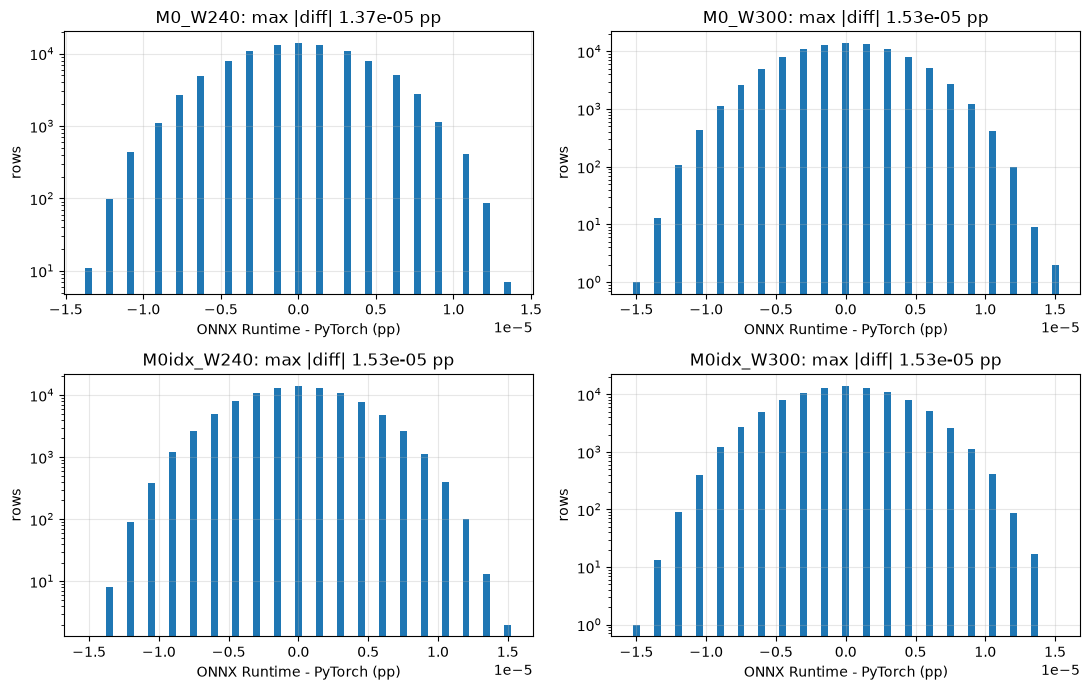

In [5]:
# S3a-d · ONNX Runtime CPU against PyTorch fp32 and the 7a verdicts
def make_session(path, intra=0):
    so = ort.SessionOptions()
    so.intra_op_num_threads = int(intra)      # 0 = ONNX Runtime default
    so.inter_op_num_threads = 1
    so.log_severity_level = 3
    return ort.InferenceSession(str(path), so, providers=["CPUExecutionProvider"])
def make_feed(name, dq32, q0, logc):
    f = {"dq32": dq32, "q0": q0}
    if MODELS[name]["idx"]: f["log_cycle"] = logc
    return f

proc = psutil.Process()
SESS_D, ORT_PRED, rss_rows, rows3a = {}, {}, [], []
for name, d in MODELS.items():
    gc.collect(); r0 = proc.memory_info().rss
    SESS_D[name] = make_session(MODEL_FILES[name], 0)
    r1 = proc.memory_info().rss
    rss_rows.append(dict(model=name, rss_before_mb=r0 / 2**20, rss_after_mb=r1 / 2**20, delta_mb=(r1 - r0) / 2**20,
                         onnx_kb=MODEL_FILES[name].stat().st_size / 1024, npz_kb=MODEL_FILES_NPZ[name].stat().st_size / 1024))
    inp = INP[d["w"]]
    out = SESS_D[name].run(["soh_pp"], make_feed(name, inp["dq32"], inp["q0"], inp["logc"]))[0][:, 0]
    ORT_PRED[name] = out
    dd = np.abs(out.astype(np.float64) - TORCH_MEAN[name])
    rows3a.append(dict(model=name, rows=len(dd), max_pp=dd.max(), p99_pp=np.percentile(dd, 99), median_pp=np.median(dd)))
    check(f"S3a ONNX Runtime CPU vs PyTorch fp32 [{name}]", dd.max() <= 1e-4, f"max {dd.max():.3e}, p99 {np.percentile(dd, 99):.3e}, median {np.median(dd):.3e} pp over {len(dd):,} rows", warn_only=dd.max() < 1e-3)
S3A = pd.DataFrame(rows3a)
show_table("S3a · |ONNX Runtime CPU - PyTorch fp32| (pp)", S3A, 4)

# (b) batch-3 cell-macro MAE from ONNX predictions
REF_VERDICT = {"M0_W300": 0.597169, "M0_W240": 0.419568}
rows3b = []
for name in MODELS:
    onnx_m = cell_macro(ORT_PRED[name][B3_IN], Y_SUB, B3_CELL_ARR)
    par_m = cell_macro(REF_MEAN[name].loc[B3_RIDS], Y_SUB, B3_CELL_ARR)
    tor_m = cell_macro(TORCH_MEAN[name][B3_IN], Y_SUB, B3_CELL_ARR)
    ref = REF_VERDICT.get(name)
    rows3b.append(dict(model=name, onnx_cell_macro_mae=onnx_m, pytorch_cell_macro_mae=tor_m, from_7a_parquet=par_m, verdict_7a=ref if ref is not None else float("nan"),
                       onnx_minus_7a_parquet=onnx_m - par_m, onnx_minus_verdict=(onnx_m - ref) if ref is not None else float("nan")))
    check(f"S3b ONNX cell-macro MAE equals the 7a parquet value to 1e-4 pp [{name}]", abs(onnx_m - par_m) <= 1e-4, f"ONNX {onnx_m:.6f}, 7a parquet {par_m:.6f}, difference {onnx_m - par_m:+.2e}")
    if ref is not None:
        check(f"S3b ONNX reproduces the 7a verdict number to 1e-4 pp [{name}]", SMOKE or abs(onnx_m - ref) <= 1e-4,
              f"ONNX {onnx_m:.6f} vs 7a verdict {ref:.6f}, difference {onnx_m - ref:+.2e}" + (" (smoke subset: verdict comparison not evaluated)" if SMOKE else ""), warn_only=SMOKE)
S3B = pd.DataFrame(rows3b)
show_table("S3b · batch-3 cell-macro MAE (pp, 40 cells)", S3B, 7)

# (c) repeatability: two fresh sessions, two runs each, identical outputs
rows3c = []
for name, d in MODELS.items():
    inp = INP[d["w"]]; n = min(10000, len(IDX_ALL))
    feed = make_feed(name, inp["dq32"][:n], inp["q0"][:n], inp["logc"][:n])
    outs = [make_session(MODEL_FILES[name], 0).run(["soh_pp"], feed)[0] for _ in range(2)]
    outs += [SESS_D[name].run(["soh_pp"], feed)[0] for _ in range(2)]
    same = all(np.array_equal(outs[0], o) for o in outs[1:])
    rows3c.append(dict(model=name, rows=n, runs=len(outs), identical=same, max_diff_pp=max(float(np.abs(outs[0] - o).max()) for o in outs[1:])))
    check(f"S3c same inputs give identical outputs across runs and sessions [{name}]", same, f"{len(outs)} runs on {n:,} rows, max difference {rows3c[-1]['max_diff_pp']:.1e}")
show_table("S3c · repeatability", pd.DataFrame(rows3c))

# (d) single-row vs batched
rows3d, rng = [], np.random.default_rng(1)
for name, d in MODELS.items():
    inp = INP[d["w"]]; sel = np.sort(rng.choice(len(IDX_ALL), min(500, len(IDX_ALL)), replace=False))
    dq, q, lc = inp["dq32"][sel], inp["q0"][sel], inp["logc"][sel]
    bat = SESS_D[name].run(["soh_pp"], make_feed(name, dq, q, lc))[0][:, 0]
    one = np.array([SESS_D[name].run(["soh_pp"], make_feed(name, dq[i:i + 1], q[i:i + 1], lc[i:i + 1]))[0][0, 0] for i in range(len(sel))], np.float32)
    dd = np.abs(bat.astype(np.float64) - one)
    rows3d.append(dict(model=name, rows=len(sel), max_diff_pp=dd.max(), median_diff_pp=np.median(dd), n_exactly_equal=int((dd == 0).sum())))
    check(f"S3d single-row vs batched outputs [{name}]", dd.max() <= 1e-6, f"max {dd.max():.2e} pp, {int((dd == 0).sum())}/{len(sel)} identical (fp32 spacing at 90 pp is 7.6e-6)", warn_only=dd.max() <= 1e-4)
show_table("S3d · single-row vs batched (pp)", pd.DataFrame(rows3d), 4)
EXTRA.update(s3a=rows3a, s3b=rows3b, s3c=rows3c, s3d=rows3d)

# parity histogram figure
fig, axs = plt.subplots(2, 2, figsize=(11, 7))
for ax, name in zip(axs.ravel(), MODELS):
    diff = ORT_PRED[name].astype(np.float64) - TORCH_MEAN[name]
    lim = max(float(np.abs(diff).max()), 1e-9)
    ax.hist(diff, bins=61, range=(-lim, lim), color="tab:blue"); ax.set_yscale("log")
    ax.set_title(f"{name}: max |diff| {np.abs(diff).max():.2e} pp"); ax.set_xlabel("ONNX Runtime - PyTorch (pp)"); ax.set_ylabel("rows"); ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig(W(OUT / "fig_parity_hist.png"), dpi=150); plt.show()

## S4 · Latency (CPU)
Model-only timing: raw inputs in, `soh_pp` out. ONNX Runtime is timed with NumPy inputs (conversion included), PyTorch with pre-built tensors under `inference_mode`. Repeats are capped by a per-configuration time budget; the repeat count actually used is in the table.

[PASS] timing modules agree (torch vs ONNX) [M0_W240] - max 1.53e-05 pp on 4,096 rows
[PASS] timing modules agree (torch vs ONNX) [M0_W300] - max 1.53e-05 pp on 4,096 rows
[PASS] timing modules agree (torch vs ONNX) [M0idx_W240] - max 1.53e-05 pp on 4,096 rows
[PASS] timing modules agree (torch vs ONNX) [M0idx_W300] - max 1.53e-05 pp on 4,096 rows

S4 · latency (ms) and throughput, CPU unless stated
---------------------------------------------------
     model             engine  batch  warmup  n_repeats  median_ms  p95_ms  p99_ms  mean_ms  rows_per_s
   M0_W240        ort_1thread      1     200       5000     0.1474   1.947    6.74   0.4884        2048
   M0_W240        ort_default      1     200       5000     0.1267   1.032   4.377   0.3346        2988
   M0_W240     torch_cpu_8thr      1     200       3165     0.9723    5.25   12.67    1.726       579.5
   M0_W240 torch_cuda (extra)      1     200        426      5.692   17.33   24.34     7.15       139.9
   M0_W240        ort_1th

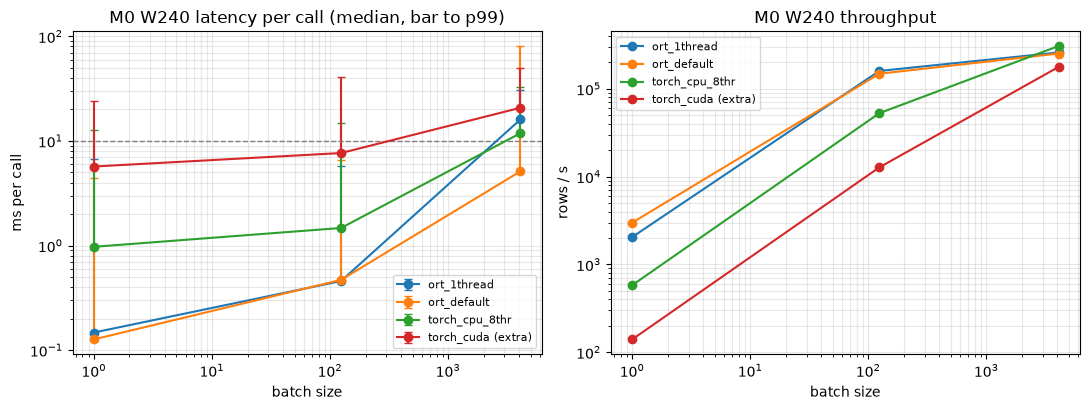

In [6]:
# S4 · latency, memory, engineering targets, optional int8
class TorchEns(torch.nn.Module):
    """Five members + scalers + mean on the 32-point input, using the module's own fc layers (same maths as the ONNX graph)."""
    def __init__(self, st, mods, uses_idx):
        super().__init__()
        self.mods, self.idx = torch.nn.ModuleList(mods), uses_idx
        g = lambda k: [torch.tensor(float(st[f"scaler_{k}"][i]), dtype=torch.float32) for i in range(len(mods))]
        self.sc = {k: g(k) for k in st["scaler_names"]}
    def to(self, *a, **k):
        super().to(*a, **k)
        self.sc = {kk: [t.to(*a, **k) for t in v] for kk, v in self.sc.items()}
        return self
    def forward(self, dq32, q0, logc=None):
        outs = []
        for i, m in enumerate(self.mods):
            parts = [dq32 / self.sc["s"][i], (q0 - self.sc["qm"][i]) / self.sc["qs"][i]]
            if self.idx: parts.append((logc - self.sc["em"][i]) / self.sc["es"][i])
            h = torch.relu(m.fc1(torch.cat(parts, 1))); h = torch.relu(m.fc2(h))
            outs.append(self.sc["ym"][i] + self.sc["ys"][i] * m.fc3(h))
        return torch.stack(outs).mean(0)

TIMING_NAMES = ["M0_W240", "M0_W300", "M0idx_W240", "M0idx_W300"]
BATCHES = [1, 124, 4096]
def timing_inputs(name, b):
    w = MODELS[name]["w"]
    if b == 124:
        _, dq, q, lc = get_inputs(w, FLEET_POS)           # one row per cell: the real fleet snapshot
        q, lc = q.reshape(-1, 1), lc.reshape(-1, 1)
    else:
        n = min(b, len(IDX_ALL)); src = INP[w]
        reps = -(-b // n)
        dq, q, lc = (np.tile(src[k][:n], (reps, 1))[:b] for k in ("dq32", "q0", "logc"))
    return [np.ascontiguousarray(a, np.float32) for a in (dq, q, lc)]

def time_calls(fn, repeats, warmup, budget=BUDGET_S):
    gc.collect(); gc.disable()
    try:
        t_w = time.perf_counter(); nw = 0
        for _ in range(warmup):
            fn(); nw += 1
            if time.perf_counter() - t_w > 5.0: break
        cal = []
        for _ in range(10):
            a = time.perf_counter(); fn(); cal.append(time.perf_counter() - a)
        n = int(np.clip(budget / max(float(np.median(cal)), 1e-9), MIN_REP, repeats))
        ts = np.empty(n)
        for i in range(n):
            a = time.perf_counter(); fn(); ts[i] = time.perf_counter() - a
    finally:
        gc.enable()
    return ts * 1e3, nw
def stats_row(ts, **kw):
    return dict(**kw, n_repeats=len(ts), median_ms=np.median(ts), p95_ms=np.percentile(ts, 95), p99_ms=np.percentile(ts, 99), mean_ms=ts.mean(),
                rows_per_s=kw["batch"] / (ts.mean() / 1e3))

lat_rows, sess_t = [], {}
for name in TIMING_NAMES:
    st = load_npz(MODEL_FILES_NPZ[name], name); d = MODELS[name]
    sess_t[(name, "ort_1thread")] = make_session(MODEL_FILES[name], 1)
    sess_t[(name, "ort_default")] = SESS_D[name]
    ens = TorchEns(st, build_members(st, WIDTH[d["w"]]), d["idx"]).eval()
    # fairness check: the torch timing module equals the exported graph
    dq, q, lc = timing_inputs(name, 4096)
    with torch.inference_mode():
        o_t = ens(torch.from_numpy(dq), torch.from_numpy(q), torch.from_numpy(lc)).numpy()[:, 0]
    o_o = sess_t[(name, "ort_1thread")].run(["soh_pp"], make_feed(name, dq, q, lc))[0][:, 0]
    check(f"timing modules agree (torch vs ONNX) [{name}]", float(np.abs(o_t - o_o).max()) < 1e-4, f"max {np.abs(o_t - o_o).max():.2e} pp on 4,096 rows")
    for b in BATCHES:
        dq, q, lc = timing_inputs(name, b); feed = make_feed(name, dq, q, lc)
        for eng in ("ort_1thread", "ort_default"):
            s = sess_t[(name, eng)]
            ts, nw = time_calls(lambda: s.run(["soh_pp"], feed), REPEATS, WARMUP)
            lat_rows.append(stats_row(ts, model=name, engine=eng, batch=b, warmup=nw))
        t_in = [torch.from_numpy(x) for x in (dq, q, lc)]
        def _tf():
            with torch.inference_mode(): return ens(*t_in) if d["idx"] else ens(t_in[0], t_in[1])
        ts, nw = time_calls(_tf, REPEATS, WARMUP)
        lat_rows.append(stats_row(ts, model=name, engine=f"torch_cpu_{TORCH_THREADS}thr", batch=b, warmup=nw))
        if CUDA and name == "M0_W240":
            ens_c = TorchEns(st, build_members(st, WIDTH[d["w"]]), d["idx"]).eval().to("cuda")
            c_in = [x.to("cuda") for x in t_in]
            def _cf():
                with torch.inference_mode(): o = ens_c(c_in[0], c_in[1])
                torch.cuda.synchronize(); return o
            ts, nw = time_calls(_cf, REPEATS, WARMUP)
            lat_rows.append(stats_row(ts, model=name, engine="torch_cuda (extra)", batch=b, warmup=nw))
LAT = pd.DataFrame(lat_rows)
show_table("S4 · latency (ms) and throughput, CPU unless stated", LAT[["model", "engine", "batch", "warmup", "n_repeats", "median_ms", "p95_ms", "p99_ms", "mean_ms", "rows_per_s"]], 4)
check("every latency configuration reached at least 100 repeats (or the smoke count)", bool((LAT.n_repeats >= MIN_REP).all()),
      f"repeats min {LAT.n_repeats.min()}, max {LAT.n_repeats.max()}; configurations below {REPEATS}: {int((LAT.n_repeats < REPEATS).sum())} of {len(LAT)}", warn_only=False)

# memory and file sizes
mem = pd.DataFrame(rss_rows)
mem["process_rss_now_mb"] = proc.memory_info().rss / 2**20
show_table("S4 · process memory (RSS, MB) around session creation, and file sizes (KB)", mem, 5)

# engineering targets (model-only; full pipeline is 8b)
dep = LAT[(LAT.model == "M0_W240") & (LAT.engine == "ort_1thread")].set_index("batch")
tgt = [dict(target="at most 10 ms per cell update (batch 1, p99, ORT 1 thread)", observed_ms=dep.loc[1, "p99_ms"], limit_ms=10.0, met=dep.loc[1, "p99_ms"] <= 10.0),
       dict(target="at most 50 ms for 124 cells (one call, p99, ORT 1 thread)", observed_ms=dep.loc[124, "p99_ms"], limit_ms=50.0, met=dep.loc[124, "p99_ms"] <= 50.0)]
for t in tgt: check("engineering target: " + t["target"], t["met"], f"observed {t['observed_ms']:.4f} ms vs limit {t['limit_ms']} ms (model only)", warn_only=True)
show_table("S4 · engineering targets, deployed M0 W240 (model only)", pd.DataFrame(tgt), 5)

# optional int8 (never the default)
INT8 = {}
if INT8_ERR is None:
    s8 = make_session(INT8_PATH, 1); inp = INP["W240"]
    o8 = s8.run(["soh_pp"], {"dq32": inp["dq32"], "q0": inp["q0"]})[0][:, 0]
    mae32 = float(S3B.set_index("model").loc["M0_W240", "onnx_cell_macro_mae"])
    mae8 = cell_macro(o8[B3_IN], Y_SUB, B3_CELL_ARR)
    dd = np.abs(o8.astype(np.float64) - ORT_PRED["M0_W240"])
    rows8 = []
    for b in BATCHES:
        dq, q, lc = timing_inputs("M0_W240", b); feed = {"dq32": dq, "q0": q}
        ts, nw = time_calls(lambda: s8.run(["soh_pp"], feed), REPEATS, WARMUP)
        r = stats_row(ts, model="M0_W240_int8", engine="ort_1thread", batch=b, warmup=nw); rows8.append(r)
        f32 = dep.loc[b]; r["median_ms_fp32"] = f32.median_ms; r["speed_ratio_fp32_over_int8"] = f32.median_ms / r["median_ms"]
    LAT8 = pd.DataFrame(rows8)
    INT8 = dict(mae_fp32=mae32, mae_int8=mae8, mae_change=mae8 - mae32, max_abs_diff=float(dd.max()), median_abs_diff=float(np.median(dd)), size_kb_int8=INT8_PATH.stat().st_size / 1024,
                size_kb_fp32=MODEL_FILES["M0_W240"].stat().st_size / 1024)
    show_table("S4 · optional int8 (dynamic quantisation) vs fp32, M0 W240 (option only, not the default)", pd.DataFrame([INT8]), 6)
    show_table("S4 · int8 latency (ms), ORT 1 thread", LAT8[["model", "batch", "n_repeats", "median_ms", "p95_ms", "p99_ms", "mean_ms", "rows_per_s", "median_ms_fp32", "speed_ratio_fp32_over_int8"]], 4)
    check("int8 batch-3 cell-macro MAE change reported", True, f"fp32 {mae32:.6f}, int8 {mae8:.6f}, change {mae8 - mae32:+.6f} pp, max |row diff| {dd.max():.4f} pp")
else:
    emit("S4 · optional int8", f"not available: {INT8_ERR}")
EXTRA.update(latency=lat_rows, int8=INT8, memory=rss_rows)

# figure: latency and throughput versus batch size
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))
for eng, g in LAT[LAT.model == "M0_W240"].groupby("engine"):
    g = g.sort_values("batch")
    axs[0].errorbar(g.batch, g.median_ms, yerr=[np.zeros(len(g)), (g.p99_ms - g.median_ms).clip(lower=0)], marker="o", capsize=3, label=eng)
    axs[1].plot(g.batch, g.rows_per_s, marker="o", label=eng)
axs[0].axhline(10, ls="--", c="grey", lw=1); axs[0].set_title("M0 W240 latency per call (median, bar to p99)")
for a, yl in zip(axs, ("ms per call", "rows / s")):
    a.set_xscale("log"); a.set_yscale("log"); a.set_xlabel("batch size"); a.set_ylabel(yl); a.grid(alpha=.3, which="both"); a.legend(fontsize=8)
axs[1].set_title("M0 W240 throughput")
fig.tight_layout(); fig.savefig(W(OUT / "fig_latency_vs_batch.png"), dpi=150); plt.show()

## S5 · Scorer module and unit test

In [7]:
# S5 · write src/onnx_scorer.py (the only file written outside outputs/phase8a)
SCORER_SRC = r"""\"\"\"ONNX Runtime scorer for the frozen phase-7a M0 SOH models (phase 8a).

Raw inputs only: the ONNX graph contains the five ensemble members, the feature scalers and the ensemble mean.

    scorer = OnnxScorer("outputs/phase8a/models/M0_W240.onnx")
    soh_pp = scorer.predict(dq32, q0)                     # M0
    soh_pp = scorer.predict(dq32, q0, log_cycle)          # M0+idx models (log1p(cycle_number))

dq32 is DeltaQ at sub_idx(L) of the window (float32, N x 32), q0 is Q0 per row, soh_pp is SOH in percentage points.
\"\"\"
import hashlib
import re
from pathlib import Path

import numpy as np


class OnnxScorer:
    def __init__(self, model_path, intra_op_threads=1):
        self.path = Path(model_path)
        if not self.path.is_file():
            raise FileNotFoundError(f"ONNX model not found: {self.path}")
        stem = self.path.stem
        m = re.fullmatch(r"(M0|M0idx)_(W\d+)", stem)
        if m is None:
            raise ValueError(f"cannot read model and window from file name {self.path.name!r}; expected M0_W240.onnx style")
        self.name, self.window = stem, m.group(2)
        self.model = m.group(1)
        self.uses_log_cycle = self.model == "M0idx"
        self._threads = int(intra_op_threads)
        self._sha = None
        self._sess = None

    @property
    def sha256(self):
        if self._sha is None:
            self._sha = hashlib.sha256(self.path.read_bytes()).hexdigest()
        return self._sha

    @property
    def session(self):
        if self._sess is None:
            import onnxruntime as ort
            so = ort.SessionOptions()
            so.intra_op_num_threads = self._threads
            so.inter_op_num_threads = 1
            so.log_severity_level = 3
            sess = ort.InferenceSession(str(self.path), so, providers=["CPUExecutionProvider"])
            names = [i.name for i in sess.get_inputs()]
            want = ["dq32", "q0"] + (["log_cycle"] if self.uses_log_cycle else [])
            if names != want:
                raise RuntimeError(f"{self.path.name}: graph inputs {names} differ from the expected {want}")
            meta = sess.get_modelmeta().custom_metadata_map
            if meta.get("window") not in (None, self.window):
                raise RuntimeError(f"{self.path.name}: metadata window {meta.get('window')!r} differs from file name window {self.window!r}")
            self._sess = sess
        return self._sess

    def _col(self, name, a, n):
        a = np.asarray(a)
        if a.dtype != np.float32:
            raise TypeError(f"{name} must be float32, got {a.dtype}")
        if a.shape == (n,):
            a = a.reshape(n, 1)
        if a.shape != (n, 1):
            raise ValueError(f"{name} must have shape ({n},) or ({n}, 1), got {a.shape}")
        return self._finite(name, a)

    @staticmethod
    def _finite(name, a):
        bad = ~np.isfinite(a)
        if bad.any():
            rows = np.unique(np.nonzero(bad)[0])
            raise ValueError(f"{name} contains {int(bad.sum())} NaN/inf value(s); first bad row index {int(rows[0])}")
        return np.ascontiguousarray(a)

    def predict(self, dq32, q0, log_cycle=None):
        dq32 = np.asarray(dq32)
        if dq32.dtype != np.float32:
            raise TypeError(f"dq32 must be float32, got {dq32.dtype}")
        if dq32.ndim != 2 or dq32.shape[1] != 32 or dq32.shape[0] < 1:
            raise ValueError(f"dq32 must have shape (N, 32) with N >= 1, got {dq32.shape}")
        n = dq32.shape[0]
        feed = {"dq32": self._finite("dq32", dq32), "q0": self._col("q0", q0, n)}
        if self.uses_log_cycle:
            if log_cycle is None:
                raise ValueError(f"{self.name} needs log_cycle (log1p of the cycle number)")
            feed["log_cycle"] = self._col("log_cycle", log_cycle, n)
        elif log_cycle is not None:
            raise ValueError(f"{self.name} takes no log_cycle input")
        out = self.session.run(["soh_pp"], feed)[0]
        return np.ascontiguousarray(out.reshape(-1), dtype=np.float32)

    def __repr__(self):
        return f"OnnxScorer(name={self.name!r}, window={self.window!r}, sha256={self.sha256[:12]}...)"
""".replace('\\"', '"')
write_text(SCORER_PATH, SCORER_SRC)
SCORER_SHA = sha256_file(SCORER_PATH)
spec = importlib.util.spec_from_file_location("onnx_scorer", SCORER_PATH); onnx_scorer = importlib.util.module_from_spec(spec); spec.loader.exec_module(onnx_scorer)
emit("onnx_scorer helper signatures", "\n".join(f"{n}{_sig(o)}" for n, o in [("OnnxScorer.__init__", onnx_scorer.OnnxScorer.__init__), ("OnnxScorer.predict", onnx_scorer.OnnxScorer.predict)]))

# unit test: all four models reproduce three stored batch-3 predictions (7a parquet ensemble mean) to 1e-4 pp
test_pos = np.unique(IDX_ALL[B3_IN][[0, len(B3_IN) // 2, -1]])
test_rows = []
for name, d in MODELS.items():
    sc_ = onnx_scorer.OnnxScorer(MODEL_FILES[name])
    _, dq32, q0, lc = get_inputs(d["w"], test_pos)
    out = sc_.predict(dq32, q0, lc if d["idx"] else None)
    ref = REF_MEAN[name].loc[ROW_ID[test_pos]].to_numpy(np.float64)
    dd = np.abs(out.astype(np.float64) - ref)
    check(f"scorer reproduces 3 stored batch-3 predictions to 1e-4 pp [{name}]", out.dtype == np.float32 and out.shape == (3,) and dd.max() <= 1e-4 and sc_.sha256 == sha256_file(MODEL_FILES[name]),
          f"rows {ROW_ID[test_pos].tolist()}, max diff {dd.max():.2e} pp, window {sc_.window}, sha256 {sc_.sha256[:12]}")
    test_rows.append(dict(model=name, window=sc_.window, sha256=sc_.sha256[:16], row_ids=",".join(map(str, ROW_ID[test_pos])), max_diff_pp=dd.max()))
show_table("S5 · scorer unit test (pp)", pd.DataFrame(test_rows), 4)

# input validation
sc0, sci = onnx_scorer.OnnxScorer(MODEL_FILES["M0_W240"]), onnx_scorer.OnnxScorer(MODEL_FILES["M0idx_W240"])
_, dq32, q0, lc = get_inputs("W240", test_pos[:2])
bad = dq32.copy(); bad[0, 3] = np.nan
inf_ = q0.copy(); inf_[1] = np.inf
cases = [("NaN in dq32", lambda: sc0.predict(bad, q0), ValueError), ("inf in q0", lambda: sc0.predict(dq32, inf_), ValueError),
         ("wrong width", lambda: sc0.predict(dq32[:, :31], q0), ValueError), ("float64 dq32", lambda: sc0.predict(dq32.astype(np.float64), q0), TypeError),
         ("q0 length mismatch", lambda: sc0.predict(dq32, q0[:1]), ValueError), ("missing log_cycle", lambda: sci.predict(dq32, q0), ValueError),
         ("unexpected log_cycle", lambda: sc0.predict(dq32, q0, lc), ValueError), ("empty batch", lambda: sc0.predict(dq32[:0], q0[:0]), ValueError)]
vrows = []
for label, fn, exc in cases:
    try: fn(); got, msg = "no error", ""
    except Exception as e: got, msg = type(e).__name__, str(e)
    vrows.append(dict(case=label, expected=exc.__name__, raised=got, message=msg))
    check(f"scorer rejects: {label}", got == exc.__name__ and len(msg) > 10, f"raised {got}: {msg}")
show_table("S5 · scorer input validation", pd.DataFrame(vrows))
log_append("scorer_written", path=str(SCORER_PATH.relative_to(ROOT)), sha256=SCORER_SHA)
EXTRA["scorer"] = dict(sha256=SCORER_SHA, tests=test_rows)


onnx_scorer helper signatures
-----------------------------
OnnxScorer.__init__(self, model_path, intra_op_threads=1)
OnnxScorer.predict(self, dq32, q0, log_cycle=None)
[PASS] scorer reproduces 3 stored batch-3 predictions to 1e-4 pp [M0_W240] - rows [63750, 66094, 73154], max diff 7.63e-06 pp, window W240, sha256 4fe196d3f778
[PASS] scorer reproduces 3 stored batch-3 predictions to 1e-4 pp [M0_W300] - rows [63750, 66094, 73154], max diff 7.63e-06 pp, window W300, sha256 4e8cd5235869
[PASS] scorer reproduces 3 stored batch-3 predictions to 1e-4 pp [M0idx_W240] - rows [63750, 66094, 73154], max diff 6.10e-06 pp, window W240, sha256 50ea2ebbf287
[PASS] scorer reproduces 3 stored batch-3 predictions to 1e-4 pp [M0idx_W300] - rows [63750, 66094, 73154], max diff 6.10e-06 pp, window W300, sha256 4c94897e3f76

S5 · scorer unit test (pp)
--------------------------
     model window           sha256           row_ids  max_diff_pp
   M0_W240   W240 4fe196d3f7787a4f 63750,66094,73154    7.629e-

## S6 · Expectations against observations

In [8]:
# S6 · expected / observed / consistent (registered in S0 before any parity or timing number; nothing is selected)
d1 = LAT[(LAT.model == "M0_W240") & (LAT.engine == "ort_1thread")].set_index("batch")
worst = float(S3A.max_pp.max())
obs = {
    "H12": (f"max {worst:.3e} pp (worst model {S3A.loc[S3A.max_pp.idxmax(), 'model']})", worst < 1e-3),
    "H13": (f"median {d1.loc[1, 'median_ms']:.4f} ms, p99 {d1.loc[1, 'p99_ms']:.4f} ms", bool(d1.loc[1, "median_ms"] < 1.0 and d1.loc[1, "p99_ms"] < 5.0)),
    "H14": (f"median {d1.loc[124, 'median_ms']:.4f} ms, p99 {d1.loc[124, 'p99_ms']:.4f} ms", bool(d1.loc[124, "median_ms"] < 5.0)),
    "H15": ((f"change {INT8['mae_change']:+.6f} pp (fp32 {INT8['mae_fp32']:.6f}, int8 {INT8['mae_int8']:.6f})", abs(INT8["mae_change"]) < 0.02) if INT8 else ("int8 not available", False)),
}
rows6 = [dict(id=e["id"], expected=e["expected"], observed=obs[e["id"]][0], consistent="yes" if obs[e["id"]][1] else "NO") for e in EXPECT]
show_table("S6 · expectations (registered before timing and parity) against observations", pd.DataFrame(rows6))
for r in rows6: check(f"{r['id']} {r['expected']}", r["consistent"] == "yes", r["observed"], warn_only=True)
EXTRA["s6"] = rows6


S6 · expectations (registered before timing and parity) against observations
----------------------------------------------------------------------------
 id                     expected                                           observed consistent
H12                    < 1e-3 pp             max 1.526e-05 pp (worst model M0_W300)        yes
H13 median < 1 ms and p99 < 5 ms                    median 0.1474 ms, p99 6.7404 ms         NO
H14                median < 5 ms                    median 0.4576 ms, p99 5.8155 ms        yes
H15           |change| < 0.02 pp change +0.005100 pp (fp32 0.419568, int8 0.424668)        yes
[PASS] H12 < 1e-3 pp - max 1.526e-05 pp (worst model M0_W300)
[WARN] H13 median < 1 ms and p99 < 5 ms - median 0.1474 ms, p99 6.7404 ms
[PASS] H14 median < 5 ms - median 0.4576 ms, p99 5.8155 ms
[PASS] H15 |change| < 0.02 pp - change +0.005100 pp (fp32 0.419568, int8 0.424668)


## S7 · Report and artifacts

In [9]:
# S7 · final guards, hash chain, CSVs, JSON, report, artifact list
GUARD_END = guard("end")
show_table("Hash guard (end)", GUARD_END)
ent = log_entries(); chain_ok, prev = True, ""
for l in [x for x in LOG_PATH.read_text(encoding="utf-8").splitlines() if x.strip()]:
    e = json.loads(l); chain_ok &= (e["prev_line_sha256"] == prev); prev = sha256_bytes(l.encode("utf-8"))
check("log hash chain intact", chain_ok and ent[0]["event"] == "start", f"{len(ent)} entries, events {[e['event'] for e in ent]}")
# nothing under frozen locations was touched by this run
check("no 7a file newer than this run's start (read-only)", all(p.stat().st_mtime < T0 for p in OUT7A.rglob("*") if p.is_file()), "mtime scan of outputs/phase7a")

# CSVs
for fn, df in [("parity_onnx_vs_pytorch.csv", S3A), ("batch3_cell_macro_mae.csv", S3B), ("pytorch_vs_7a.csv", S1_TABLE), ("latency.csv", LAT), ("expectations_vs_observed.csv", pd.DataFrame(rows6)),
               ("memory_and_sizes.csv", mem), ("onnx_exports.csv", pd.DataFrame(export_rows))] + ([("int8_vs_fp32.csv", pd.DataFrame([INT8]))] if INT8 else []):
    df.to_csv(W(OUT / fn), index=False)
runtime_s = time.time() - T0
log_append("done", runtime_s=round(runtime_s, 1), n_checks=len(CHECKS), n_fail=sum(c["status"] == "FAIL" for c in CHECKS), onnx_sha256=onnx_sha, scorer_sha256=SCORER_SHA,
           guard_end_ok=bool(GUARD_END["match"].all()))
dump_report()

def size_row(p): return dict(path=str(Path(p).relative_to(ROOT)), size_kb=round(Path(p).stat().st_size / 1024, 1))
arts = sorted([p for p in OUT.rglob("*") if p.is_file() and p.name != "phase8a_report.txt"]) + [SCORER_PATH]
ART = pd.DataFrame([size_row(p) for p in arts] + [dict(path=str((OUT / "phase8a_report.txt").relative_to(ROOT)), size_kb=float("nan"))])
show_table("Artifacts (report size not listed: it is written after this table)", ART, 5)
emit("Runtime", f"{runtime_s:.0f} s ({runtime_s / 60:.1f} min), SMOKE={SMOKE}")
n = {k: sum(c["status"] == k for c in CHECKS) for k in ("PASS", "WARN", "FAIL")}
head = ["PHASE 8a - ONNX EXPORT, PARITY AND LATENCY", "=" * 78, f"generated {now_utc()} | SMOKE={SMOKE}" + (" | SMOKE RESULTS ARE NEVER QUOTED" if SMOKE else ""),
        f"checks: {n['PASS']} PASS, {n['WARN']} WARN, {n['FAIL']} FAIL", ""]
body = [f"{t}\n{'-' * len(t)}\n{x}\n" for t, x in TABLES]
chk = ["CHECKS", "-" * 6] + [f"[{c['status']}] {c['name']}" + (f" - {c['detail']}" if c["detail"] else "") for c in CHECKS]
write_text(OUT / "phase8a_report.txt", "\n".join(head + body + chk) + "\n")
print(f"\nphase8a_report.txt written ({(OUT / 'phase8a_report.txt').stat().st_size / 1024:.1f} KB) | {n}")
assert n["FAIL"] == 0

[PASS] [end] sha256 M0_W240.npz - M0_W240.npz: got 29cd3ec8c5c2113db1d1b3562365461f3045f07b5e3113532f28eeff34c744fe
[PASS] [end] sha256 M0_W300.npz - M0_W300.npz: got 06f63dc6c5a89750d18622099961e875ee1aeb1b65d9afe16b556f0d7cb149c2
[PASS] [end] sha256 M0idx_W240.npz - M0idx_W240.npz: got b7822335aa1c7cb592e4a12e3044c614a3b2616b2a5be5c940b47579862f8e18
[PASS] [end] sha256 M0idx_W300.npz - M0idx_W300.npz: got 0e7430ee1586a57b38207ce95e7d73b902b230678a92c0f32a4a704e5c05e99e
[PASS] [end] sha256 batch3_predictions.parquet - batch3_predictions.parquet: got 679ec76862de63f2615a710c7fc1f3ca2ec6c01149735bdd909b95ad5a9c7acd
[PASS] [end] sha256 soh_deep_v4.py - soh_deep_v4.py: got 2be9ce5ded197b16028079e7d34b550c683f4152b528f55f5064251b146eded4
[PASS] [end] sha256 monitor_config - monitor_config.json: got 638b6c3a6ad31c699fb77a22eb9fae72b571d6dc21ee65a73b41e849d7acb4b2
[PASS] [end] sha256 monitor_config_addendum - monitor_config_addendum.json: got d842e5f4c3186889ce8292e0654e1a0ca29d4434bcdeaf1bd